# Relative position of introns in ciliate genes

Hypothesized mechanism for intron loss is homologous recombination from cDNAs produced by reverse transcription of RNA transcripts. Because reverse transcription proceeds from the 3'-end of the transcripts, but premature truncation of reverse transcription is common, there should be a bias for losing introns towards the 3' end of genes, i.e. introns should be more abundant towards the 5' end of genes in genomes that have experienced intron loss. See https://doi.org/10.1016/S0378-1119(02)01035-1, https://doi.org/10.1016/j.gene.2004.05.027, 

We want to produce plots like Figure 1 of https://doi.org/10.1016/j.tig.2005.10.006 to see intron density and 5' bias of intron position.

Generally the fewer introns per gene on average, the more likely are introns to be positioned closer to the 5' end of the gene. Does this hold true for ciliates too?

# TODO
 * Count in-frame stops for introns across all species, compare length distributions thereof
 * Can't rely on the "phase" field in annotation files - inconsistently applied. 
 * Do ambiguous genetic codes have an effect on intron distributions? Gene predictions for Condy would help as a second data point alongside Loxodes

In [38]:
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import re
import pysam

Gene annotations hosted on ciliates.org and ParameciumDB; Entodinium caudatum data provided by Zhongtang Yu.

Sources documented in `annot/annotation-sources.yaml`

In [106]:
sp2file = {
    'lmag' : 'annot/falcon-comb_LmagMAC.pogigwasc_realtrons.gff3',
    'scoe' : 'annot/S_coeruleus_Nov2016.gff3',
    # 'spyr' : 'annot/stentor_pyriformis.gff', # gene prediction has no introns
    'bsto' : 'annot/Bsto_ATCC_MAC_Jan_09_2022.gff',
    'slem' : 'annot/stylo.gff3',
    'otri' : 'annot/O_trifallax_2020-upd3.gff3',
    'evan' : 'annot/Euplotes_vannus_Mar2018.gff3',
    'pcar' : 'annot/Pse_carnea_Jun2021.gff3', # Pseudokeronopsis
    'pfla' : 'annot/Pse_flava_Jun2021.gff3',
    'ecau' : 'annot/Ent_caudatum/Ent_caudautm.gff', # Entodinium caudatum
    'ecau2': 'genepred/braker_out/braker.gtf', # reannotation
    'tbor' : 'annot/Tetrahymena_borealis_mac_genome_v1.gff3',
    'tell' : 'annot/Tetrahymena_elliotti_mac_genome_v1.gff3',
    'tmal' : 'annot/Tetrahymena_malaccensis_mac_genome_v1.gff3',
    'tthe' : 'annot/Tetrahymena_thermophila_mac_genome_v5.gff3',
    'imul' : 'annot/img1_0407.gff3',
    'ptet' : 'annot/ptetraurelia_mac_51_annotation_v2.0.gff3',
    'pbia' : 'annot/pbiaurelia_V1-4_annotation_v2.0.gff3',
    'pbur' : 'annot/pbursaria_HK1_mac_JV3_4_annotation_v1.0.gff3',
    'pcau' : 'annot/pcaudatum_43c3d_annotation_v2.0.gff3',
    'pson' : 'annot/psonneborni_ATCC_30995_annotation_v1.0.gff3',
}   

In [100]:
def parse_augustus_gff_line(line):
    # because they have to do it differently
    if not line.startswith("#"):
        keys = ["seqid", "source", "type_", "start", "end", "score", "strand", "phase", "attr"]
        spl = line.rstrip().split("\t")
        if len(spl) == len(keys):
            out = dict(zip(keys, spl))
            out["start"] = int(out["start"]) - 1 # convert to zero-based exclusive numbering
            out["end"] = int(out["end"])
            if out["attr"] and out["type_"] == "gene":
                out["attrdict"] = {"ID": out["attr"] }
            elif "gene_id" in out["attr"]:
                out["attrdict"] = { "Parent" : re.search(r"gene_id \"([^\"]+)\";", out["attr"]).groups()[0] }
            return out

In [101]:
def parse_gff_line(line):
    if not line.startswith("#"):
        keys = ["seqid", "source", "type_", "start", "end", "score", "strand", "phase", "attr"]
        spl = line.rstrip().split("\t")
        if len(spl) == len(keys):
            out = dict(zip(keys, spl))
            out["start"] = int(out["start"]) - 1 # convert to zero-based exclusive numbering
            out["end"] = int(out["end"])
            if out["attr"] and '=' in out['attr']: # At least one key-value pair separated by '='
                try:
                    out["attrdict"] = {i.lstrip().rstrip().split("=")[0] : i.lstrip().rstrip().split("=")[1] for i in out["attr"].rstrip(";").split(";")}
                except IndexError:
                    pass
                    # print(out['attr'])
            return out

def gene2feature(gff_lines, feature='CDS'):
    """Feature coordinates keyed by parent gene ID"""
    out = defaultdict(list)
    for i in gff_lines:
        (start, end) = (i['start'],i['end']) if i['strand']=='+' else (i['end'],i['start'])
        if i['type_'] == feature:
            if 'Parent' in i['attrdict']: # skip orphan features without parents
                gene = i['attrdict']['Parent']
                out[gene].append((start,end))
    return out

def intron_relpos_lens(gene2cds):
    """Relative position of introns within total coding sequence"""
    intron_relpos = []
    intron_lens = []
    for i in gene2cds:
        if len(gene2cds[i]) > 1:
            if all([cds[0] > cds[1] for cds in gene2cds[i]]): # reverse
                s = sorted(gene2cds[i], key=lambda x: -x[0])
                lens = [j[0]-j[1] for j in s]
            elif all([cds[0] < cds[1] for cds in gene2cds[i]]):
                s = sorted(gene2cds[i], key=lambda x: x[0])
                lens = [j[1]-j[0] for j in s] # cds lengths
            else: # mixed orientations in a single gene?! this is an artefact in some annotations
                # print("mixed orientations")
                continue
            cumul = [sum(lens[0:j]) for j in range(1, len(lens))]
            if sum(lens) == 0:
                print(i)
                print(gene2cds[i])
            relpos = [j/sum(lens) for j in cumul]
            lens = [abs(s[i+1][0] - s[i][1]) for i in range(len(s)-1)]
            intron_relpos.extend(relpos)
            intron_lens.extend(lens)
    return intron_relpos, intron_lens

In [102]:
gff = {}
for sp in sp2file:
    print(sp)
    with open(sp2file[sp], 'r') as fh:
        if sp in ["ecau", "ecau2"]:
            gff[sp] = [parse_augustus_gff_line(line) for line in fh if not line.startswith("#")]
            gff[sp] = [i for i in gff[sp] if i]
        else:
            gff[sp] = [parse_gff_line(line) for line in fh if not line.startswith("#")]
            gff[sp] = [i for i in gff[sp] if i] # null lines

lmag
scoe
bsto
slem
otri
evan
pcar
pfla
ecau
ecau2
tbor
tell
tmal
tthe
imul
ptet
pbia
pbur
pcau
pson


In [103]:
len(gff)

20

In [104]:
cds_by_sp = {}
for sp in gff:
    if sp in ['evan','otri']: # these annotations don't have CDS features, use exon features instead (not much diff)
        cds_by_sp[sp] = gene2feature(gff[sp], 'exon')
    else: 
        cds_by_sp[sp] = gene2feature(gff[sp], 'CDS')

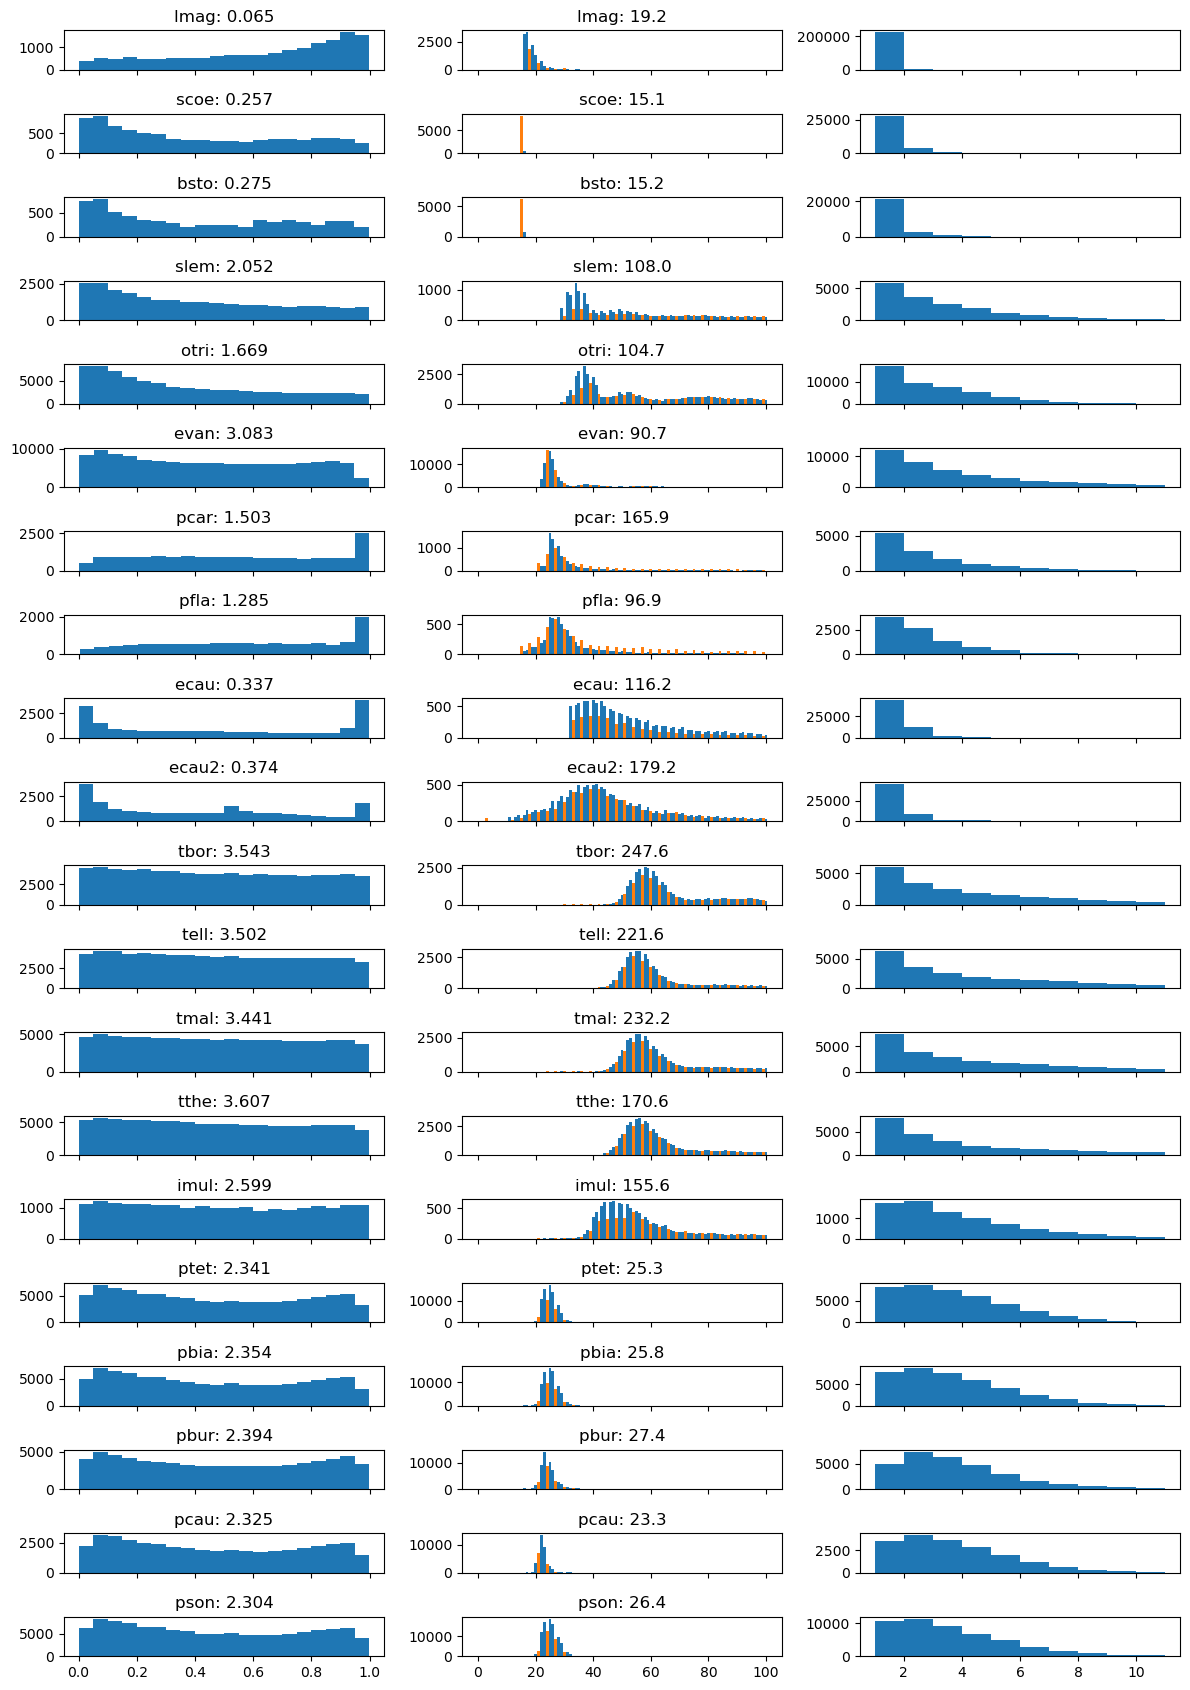

In [105]:
fig, axs = plt.subplots(nrows=len(cds_by_sp), ncols=3, figsize=(12,17), sharey=False, sharex='col')
for i in range(len(sp2file)):
    sp = list(sp2file.keys())[i]
    relpos, lens = intron_relpos_lens(cds_by_sp[sp])
    lencounts = Counter(lens)
    introns_per_gene = sum([len(j) - 1 for j in list(cds_by_sp[sp].values())])/len(cds_by_sp[sp])
    # Relative position of introns within concatenated coding sequence
    axs[i][0].hist(relpos, bins=20)
    axs[i][0].set_title(sp + ": " + str(round(introns_per_gene,3)))
    # Intron length
    ctr = Counter(lens)
    ctr = {i : ctr[i] for i in ctr if i <= 100}
    xx = list(ctr.keys())
    yy = list(ctr.values())
    ctr3 = {i : ctr[i] for i in ctr if i%3 == 0}
    xx3 = list(ctr3.keys())
    yy3 = list(ctr3.values())
    axs[i][1].bar(xx, yy, width=1)
    axs[i][1].bar(xx3, yy3, width=1, fill='red') # color 3n introns
    axs[i][1].set_title(sp + ": " + str(round(sum(lens)/len(lens),1)))
    # Exons per gene
    axs[i][2].hist([len(cds_by_sp[sp][j]) for j in cds_by_sp[sp] if len(cds_by_sp[sp][j]) < 11], bins=range(1,12)) # truncated at 10
fig.tight_layout()

Observations:

 * Phylogenetic inertia: closely related species have similar intron parameters
 * Tetrahymena is most like a "typical" eukaryote: longest introns on average, least skew in the relative distribution of introns in gene
 * Heterotrichs and spirotrichs have 5' bias in intron location in gene. They also have fewer introns per gene on average, especially the heterotrichs.
 * Loxodes is the outlier: it has 3' bias in intron location.
   * May be a consequence of its context-dependent stop codons
   * Current theory is that those codons are interpreted as termination when close to the 3' end of gene, otherwise they are translated.
   * Nonsense-mediated decay would hence be less effective at dealing with premature stops introduced by unspliced introns, especially if they are closer to 5' end of the gene. 
   * Introns closer to the 5' end of gene would be selected against, because they are more likely to produce a nonfunctional, deleterious product when translated through. Over time, there will be a bias for introns to be located closer to the 3' end of genes
   * Given that introns closer to the 3' end are more likely to be eliminated by cDNA recombination, this double squeeze could lead to a net loss of introns over time in some lineages.
   * Incidentally, Loxodes has a lower intron density than other ciliate genomes, but we should be cautious because it may be caused by overprediction of (intronless) genes in non-coding regions. (The intron features themselves are empirically annotated from RNAseq mappings so should not be gene prediction artefacts.)
   * We should test whether Condylostoma has a similar bias -- but genome is not yet annotated
   * But: cannot rule out a systematic problem with the gene prediction. Should inspect RNAseq alignments to make sure that genes are not systematically truncated at 3' end.
 * Problem with Pseudokeronopsis: pronounced 3' skew in the intron position and enriched in 3n introns. I think that the gene prediction has problems, see below.

Pseudokeronopsis 3' introns:
 * I've checked that this wasn't an error in parsing reverse complemented genes
 * Could be a problem with gene prediction parameterization. Best to check empirically by mapping RNAseq data to reference genome.
 * I think it is a model parameterization problem, after inspecting a number of these short, 3'-positioned introns
 * Many of them contribute to extending the total coding sequence slightly by circumventing one or more stop codons that are in the frame of the penultimate predicted CDS segment
 * However we expect tandem stop codons immediately downstream of the canonical stop in most ciliate transcripts
 * If the gene predictor is incentivized to maximize CDS lengths and minimize stop codons, but is not aware of tandem in-frame stops, it may attempt to 'dance around' them by inserting spurious introns close to the 3' end of genes.
 * Inspection of RNAseq read mapping (libary SRR15145271 vs. P. carnea assembly from ciliates.org): poor overlap of gene predictions with RNAseq mapping, although this may be simply be due to insufficient representativeness of the expressed genes (mapping rate of ~75% is ok).
 * Virtually no reads observed that map to the longest contigs, on which many genes are predicted. 
 * Observed numerous indels relative to the reference assembly. I thought that there could have been a mixup in the samples (the taxon ID for the SRA project is P. carnea, but for the read files themselves is P. flava -- ??), so I mapped the nominal P. flava reads vs. the P carnea assembly, but that had a mapping rate of ~1%.

# Empirical introns (from RNAseq mapping)

## Pseudokeronopsis carnea

To compare against gene predictions that I think are faulty.

Mapping with hisat2, min intron length 20 and max length 500.

In [61]:
pcar_bam = pysam.AlignmentFile("map/SRR15145271.pcar.hisat2.sort.bam", "rb")

pcar_rnaseq_introns = {}
for ctg in pcar_bam.references:
    pcar_rnaseq_introns[ctg] = pcar_bam.find_introns((read for read in pcar_bam.fetch(contig=ctg)))

In [72]:
ii = []
for ctg in pcar_rnaseq_introns:
    if len(pcar_rnaseq_introns[ctg]) > 0:
        for coord in pcar_rnaseq_introns[ctg]:
            ii.append({'len' : coord[1]-coord[0], 'cov' : pcar_rnaseq_introns[ctg][coord]})
            #print("\t".join([str(i) for i in [ctg, coord[0], coord[1], pcar_rnaseq_introns[ctg][coord]]]))

ctr = Counter([i['len'] for i in ii if i['len']<=100 and i['cov']>5])
xx = list(ctr.keys())
yy = list(ctr.values())

In [78]:
relpos, lens = intron_relpos_lens(cds_by_sp['pcar'])

ctr_pred = Counter([i for i in lens if i<=100])
xx_pred = list(ctr_pred.keys())
yy_pred = list(ctr_pred.values())

<BarContainer object of 81 artists>

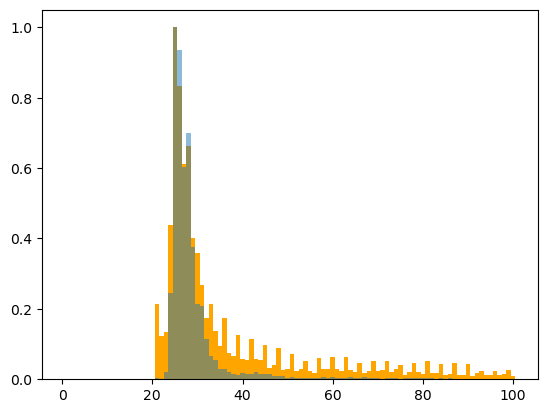

In [85]:
# Empirical vs. predicted intron length distribution (peaks scaled against highest peak)
plt.bar(xx_pred, [y/max(yy_pred) for y in yy_pred], width=1, color="orange") # predicted
plt.bar(xx, [y/max(yy) for y in yy], width=1, alpha=0.5) # empirical

Empirical introns have narrower length distribution. The weird peaks of 3n introns seen in the predicted genes are not present in the empirical set.

What is verified empirically: Modal length of 25 bp, and depletion of 27 bp introns.

## Condylostoma magnum

Mapped with modified hisat2 with min intron length 9 and max intron length 500.

In [105]:
cmag_bam = pysam.AlignmentFile("map/SRR1296902.cmag.hisat2.sort.bam", "rb")

cmag_rnaseq_introns = {}
for ctg in cmag_bam.references:
    cmag_rnaseq_introns[ctg] = cmag_bam.find_introns((read for read in cmag_bam.fetch(contig=ctg)))

In [106]:
ii = []
for ctg in cmag_rnaseq_introns:
    if len(cmag_rnaseq_introns[ctg]) > 0:
        for coord in cmag_rnaseq_introns[ctg]:
            ii.append({'len' : coord[1]-coord[0], 'cov' : cmag_rnaseq_introns[ctg][coord]})

ctr = Counter([i['len'] for i in ii if i['len']<=100 and i['cov']>5])
xx = list(ctr.keys())
yy = list(ctr.values())

<BarContainer object of 52 artists>

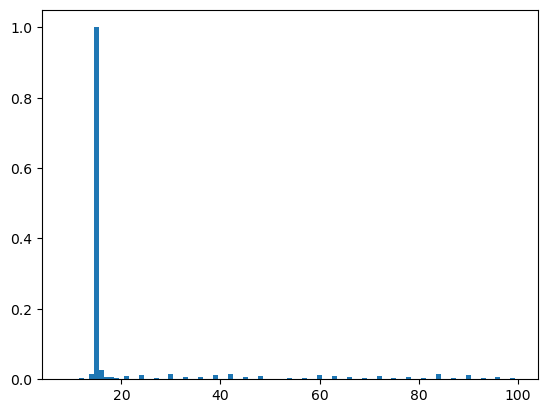

In [108]:
plt.bar(xx, [y/max(yy) for y in yy], width=1) # empirical

## Entodinium caudatum

In [ ]:
ecau_bam = pysam.AlignmentFile("map/SRR8478280.ecau.hisat2.sort.bam", "rb")

ecau_rnaseq_introns = {}
for ctg in ecau_bam.references:
    ecau_rnaseq_introns[ctg] = ecau_bam.find_introns((read for read in ecau_bam.fetch(contig=ctg)))

In [ ]:
ii = []
for ctg in ecau_rnaseq_introns:
    if len(ecau_rnaseq_introns[ctg]) > 0:
        for coord in ecau_rnaseq_introns[ctg]:
            ii.append({'len' : coord[1]-coord[0], 'cov' : ecau_rnaseq_introns[ctg][coord]})

ctr = Counter([i['len'] for i in ii if i['len']<=1000 and i['cov']>5]) # coverge above 5
xx = list(ctr.keys())
yy = list(ctr.values())

In [68]:
support = [ecau_rnaseq_introns[ctg][coords] for ctg in ecau_rnaseq_introns for coords in ecau_rnaseq_introns[ctg]]

In [71]:
support_ctr = Counter(support)

(-2.0, 50.0)

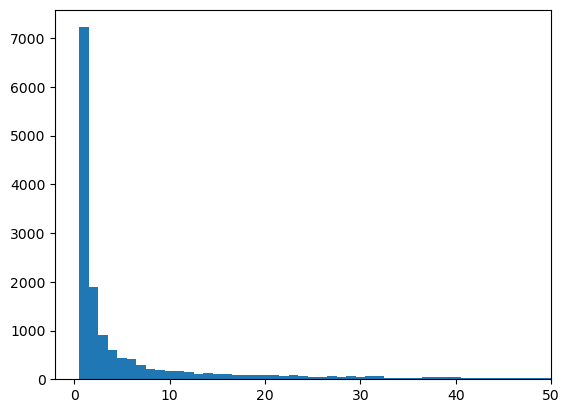

In [75]:
plt.bar(support_ctr.keys(), support_ctr.values(), width=1)
plt.xlim(-2,50)

In [59]:
xx3 = [i for i in ctr if i % 3 == 0]
yy3 = [ctr[i] for i in xx3]
xx12 = [i for i in ctr if i % 3 != 0]
yy12 = [ctr[i] for i in xx12]

In [60]:
sum(ctr.values())

6433

(0.0, 100.0)

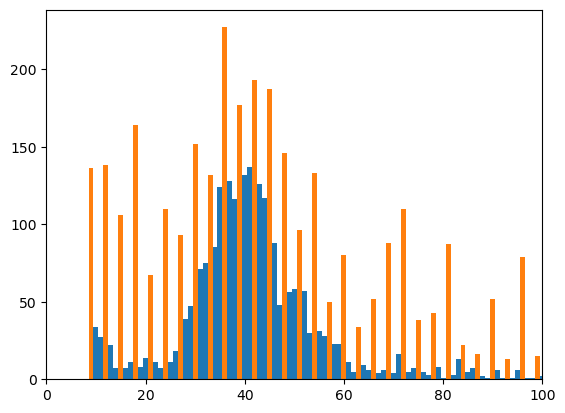

In [62]:
plt.bar(xx12, yy12, width=1)
plt.bar(xx3, yy3, width=1) # multiple of 3
plt.xlim(0,100)

<BarContainer object of 138 artists>

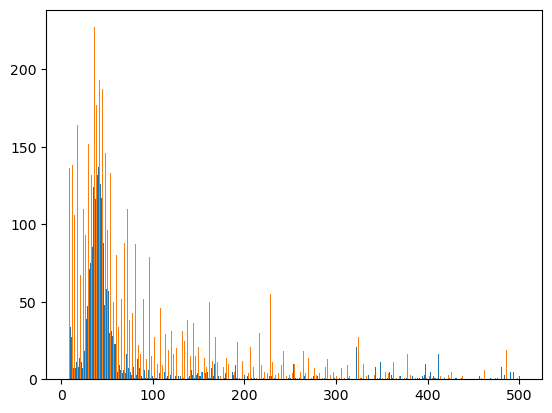

In [64]:
plt.bar(xx12, yy12, width=1)
plt.bar(xx3, yy3, width=1) # multiple of 3

In [56]:
len(cds_by_sp['ecau'])

58846

# Re-annotation of Entodinium caudatum with BRAKER3

In [78]:
import pandas as pd

In [80]:
df = pd.read_table("genepred/braker_out/braker.gtf", names=["seqid", "source", "type_", "start", "end", "score", "strand", "phase", "attr"])

In [87]:
intron_lens = df.query('type_=="intron"')['end'] - df.query('type_=="intron"')['start'] + 1

In [88]:
intron_lens_hist = Counter(intron_lens)

In [89]:
xx3 = [i for i in intron_lens_hist if i % 3 == 0]
yy3 = [intron_lens_hist[i] for i in xx3]
xx12 = [i for i in intron_lens_hist if i % 3 != 0]
yy12 = [intron_lens_hist[i] for i in xx12]

(0.0, 100.0)

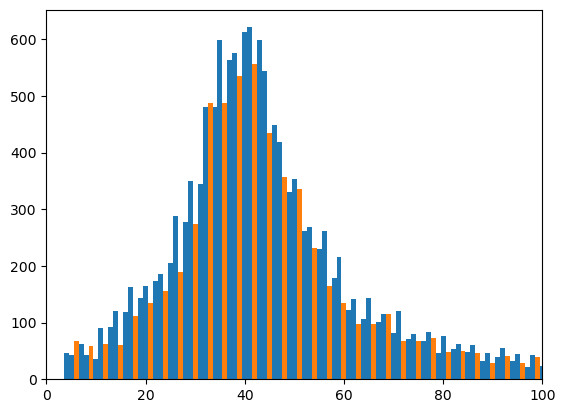

In [90]:
plt.bar(xx12, yy12, width=1)
plt.bar(xx3, yy3, width=1) # multiple of 3
plt.xlim(0,100)